# Phase 4: High-Cardinality Feature Analysis

This notebook investigates categorical cardinality and sparsity across the isolated training partition (`X_train`, `y_train`) of the California (CA) 2018 ACSIncome dataset.

### Objectives:
1. Profile cardinality across all categorical features in `X_train`.
2. Save summary to `results/04_training_cardinality_summary.csv`.
3. Select and isolate the feature with the highest unique categories (`OCCP`).
4. Perform in-depth sparsity analysis (counts for $=1$, $<10$, $<50$, $<100$ observations).
5. Generate visualizations:
   - `figures/04_high_cardinality_top_categories.png`
   - `figures/04_high_cardinality_frequency_distribution.png`
   - `figures/04_high_cardinality_cumulative_frequency.png`
6. Export selected feature name and detailed frequency table to `results/`.
7. Conclude on identifier characteristics and asymptotic $\chi^2$ validity under high cardinality.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150

# Resolve paths
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name in ['notebooks', 'src'] else NOTEBOOK_DIR

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

X_TRAIN_PATH = DATA_PROCESSED_DIR / "X_train.csv"
Y_TRAIN_PATH = DATA_PROCESSED_DIR / "y_train.csv"

print(f"Project root: {PROJECT_ROOT}")
print(f"X_train path: {X_TRAIN_PATH} (Exists: {X_TRAIN_PATH.exists()})")
print(f"y_train path: {Y_TRAIN_PATH} (Exists: {Y_TRAIN_PATH.exists()})")


Project root: D:\Github Repo\C-Square
X_train path: D:\Github Repo\C-Square\data\processed\X_train.csv (Exists: True)
y_train path: D:\Github Repo\C-Square\data\processed\y_train.csv (Exists: True)


In [2]:
# Task 1 & 2: Identify categorical columns and compute cardinality metrics
X_train = pd.read_csv(X_TRAIN_PATH)
y_train = pd.read_csv(Y_TRAIN_PATH).squeeze()

n_rows = len(X_train)
print(f"Loaded X_train with {n_rows:,} rows and {X_train.shape[1]} columns.\n")

categorical_cols = ['COW', 'SCHL', 'MAR', 'OCCP', 'POBP', 'RELP', 'SEX', 'RAC1P']

cardinality_records = []
for col in categorical_cols:
    vc = X_train[col].value_counts()
    n_unique = int(X_train[col].nunique())
    n_missing = int(X_train[col].isnull().sum())
    top_cat = vc.index[0]
    top_freq = int(vc.iloc[0])
    lt_10 = int((vc < 10).sum())
    lt_50 = int((vc < 50).sum())
    lt_100 = int((vc < 100).sum())
    card_ratio = round(n_unique / n_rows, 6)
    
    cardinality_records.append({
        "column_name": col,
        "unique_categories": n_unique,
        "missing_values": n_missing,
        "most_frequent_category": top_cat,
        "frequency_most_frequent": top_freq,
        "categories_lt_10": lt_10,
        "categories_lt_50": lt_50,
        "categories_lt_100": lt_100,
        "cardinality_ratio": card_ratio,
    })

cardinality_df = pd.DataFrame(cardinality_records)
print("=" * 85)
print("CATEGORICAL CARDINALITY SUMMARY (X_train):")
print("=" * 85)
print(cardinality_df.to_string(index=False))


Loaded X_train with 154,204 rows and 10 columns.

CATEGORICAL CARDINALITY SUMMARY (X_train):
column_name  unique_categories  missing_values  most_frequent_category  frequency_most_frequent  categories_lt_10  categories_lt_50  categories_lt_100  cardinality_ratio
        COW                  8               0                     1.0                   100737                 0                 0                  0           0.000052
       SCHL                 24               0                    21.0                    36970                 0                 0                  3           0.000156
        MAR                  5               0                     1.0                    81755                 0                 0                  0           0.000032
       OCCP                529               0                   440.0                     4431                23               172                271           0.003431
       POBP                218               0           

In [3]:
# Task 3: Save summary table to results/04_training_cardinality_summary.csv
summary_csv_path = RESULTS_DIR / "04_training_cardinality_summary.csv"
cardinality_df.to_csv(summary_csv_path, index=False)
print(f"Saved cardinality summary table to: {summary_csv_path}")


Saved cardinality summary table to: D:\Github Repo\C-Square\results\04_training_cardinality_summary.csv


In [4]:
# Task 4: Identify the categorical feature with highest unique categories
highest_card_row = cardinality_df.sort_values(by="unique_categories", ascending=False).iloc[0]
selected_feature = str(highest_card_row["column_name"])
unique_count = int(highest_card_row["unique_categories"])

print("=" * 70)
print(f"HIGHEST CARDINALITY FEATURE IDENTIFIED:")
print(f"Feature Name:              {selected_feature}")
print(f"Unique Categories Count:   {unique_count}")
print(f"Cardinality Ratio:         {highest_card_row['cardinality_ratio']:.6f}")
print("=" * 70)


HIGHEST CARDINALITY FEATURE IDENTIFIED:
Feature Name:              OCCP
Unique Categories Count:   529
Cardinality Ratio:         0.003431


In [5]:
# Task 5: Detailed sparsity calculation for selected feature (OCCP)
occp_series = X_train[selected_feature]
occp_vc = occp_series.value_counts()
n_categories = len(occp_vc)
n_observations = len(occp_series)

cat_once = int((occp_vc == 1).sum())
cat_lt_10 = int((occp_vc < 10).sum())
cat_lt_50 = int((occp_vc < 50).sum())
cat_lt_100 = int((occp_vc < 100).sum())

obs_rare_100 = int(occp_vc[occp_vc < 100].sum())
pct_obs_rare_100 = (obs_rare_100 / n_observations) * 100
pct_cats_rare_100 = (cat_lt_100 / n_categories) * 100

print("=" * 70)
print(f"SPARSITY METRICS FOR {selected_feature}:")
print("=" * 70)
print(f"Total Unique Categories:                           {n_categories}")
print(f"Total Observations in X_train:                     {n_observations:,}")
print(f"Categories appearing only ONCE:                    {cat_once} ({cat_once / n_categories:.2%})")
print(f"Categories appearing FEWER THAN 10 times:          {cat_lt_10} ({cat_lt_10 / n_categories:.2%})")
print(f"Categories appearing FEWER THAN 50 times:          {cat_lt_50} ({cat_lt_50 / n_categories:.2%})")
print(f"Categories appearing FEWER THAN 100 times:         {cat_lt_100} ({pct_cats_rare_100:.2f}%)")
print(f"Observations in rare categories (< 100 count):     {obs_rare_100:,} ({pct_obs_rare_100:.2f}%)")
print(f"Percentage of categories that are rare (< 100):    {pct_cats_rare_100:.2f}%")
print("=" * 70)


SPARSITY METRICS FOR OCCP:
Total Unique Categories:                           529
Total Observations in X_train:                     154,204
Categories appearing only ONCE:                    2 (0.38%)
Categories appearing FEWER THAN 10 times:          23 (4.35%)
Categories appearing FEWER THAN 50 times:          172 (32.51%)
Categories appearing FEWER THAN 100 times:         271 (51.23%)
Observations in rare categories (< 100 count):     11,326 (7.34%)
Percentage of categories that are rare (< 100):    51.23%


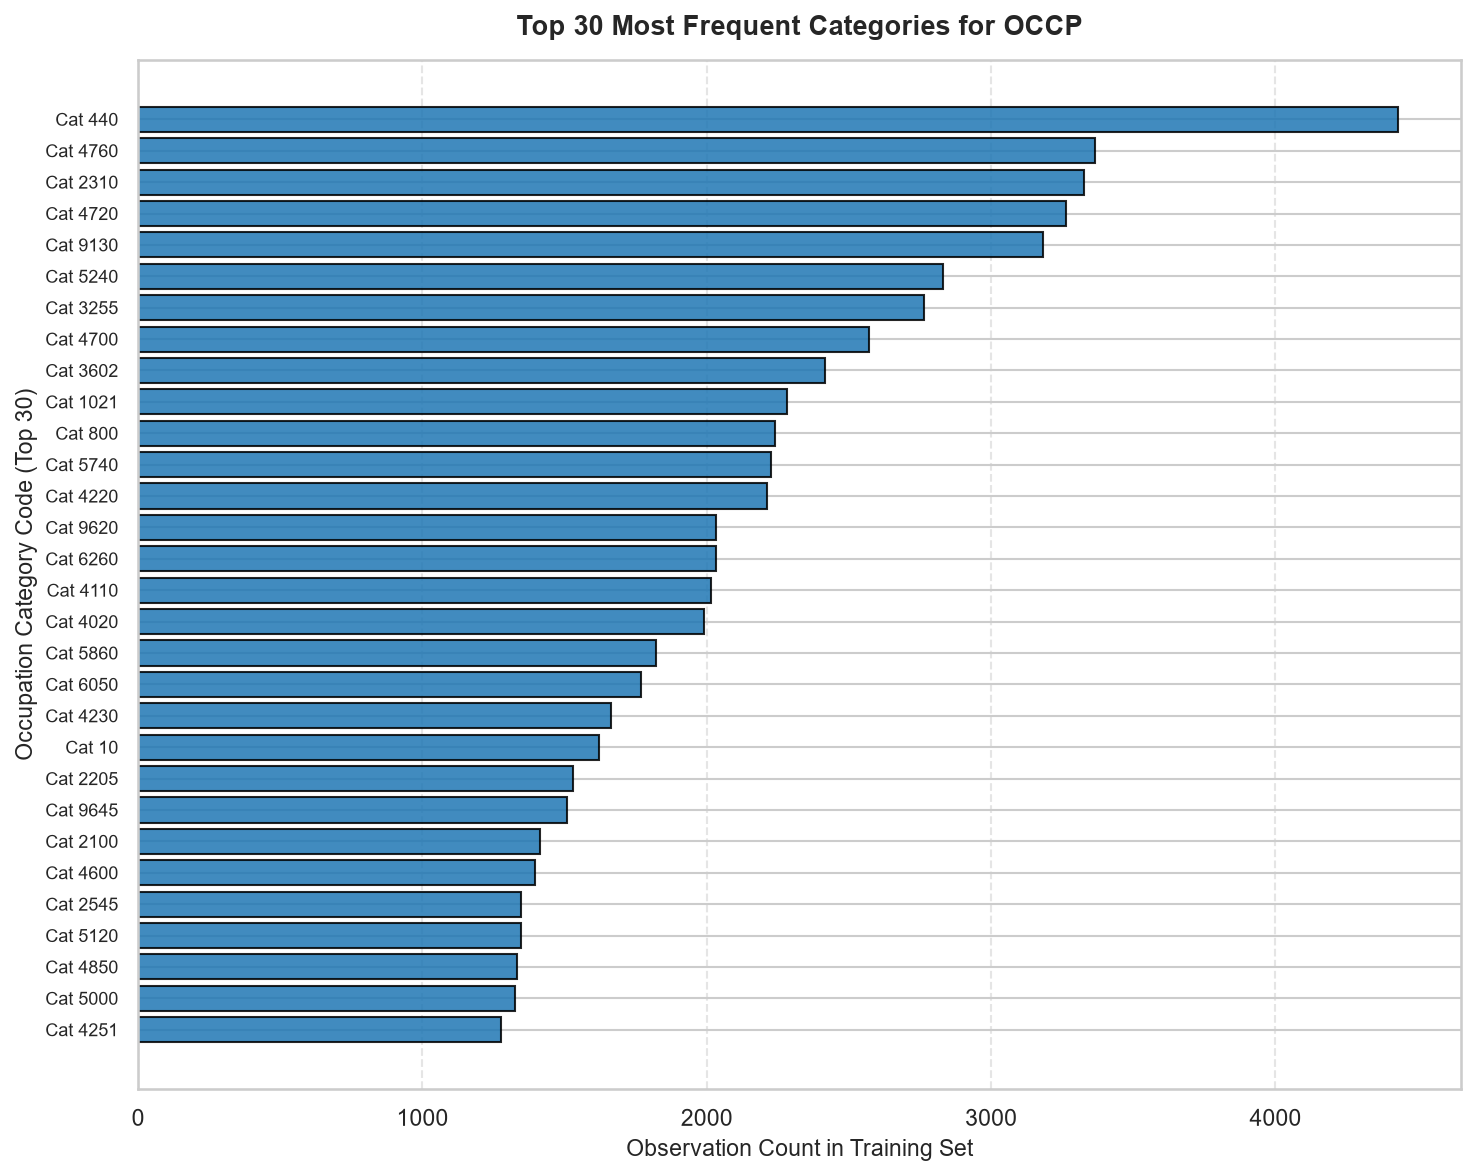

Saved: D:\Github Repo\C-Square\figures\04_high_cardinality_top_categories.png


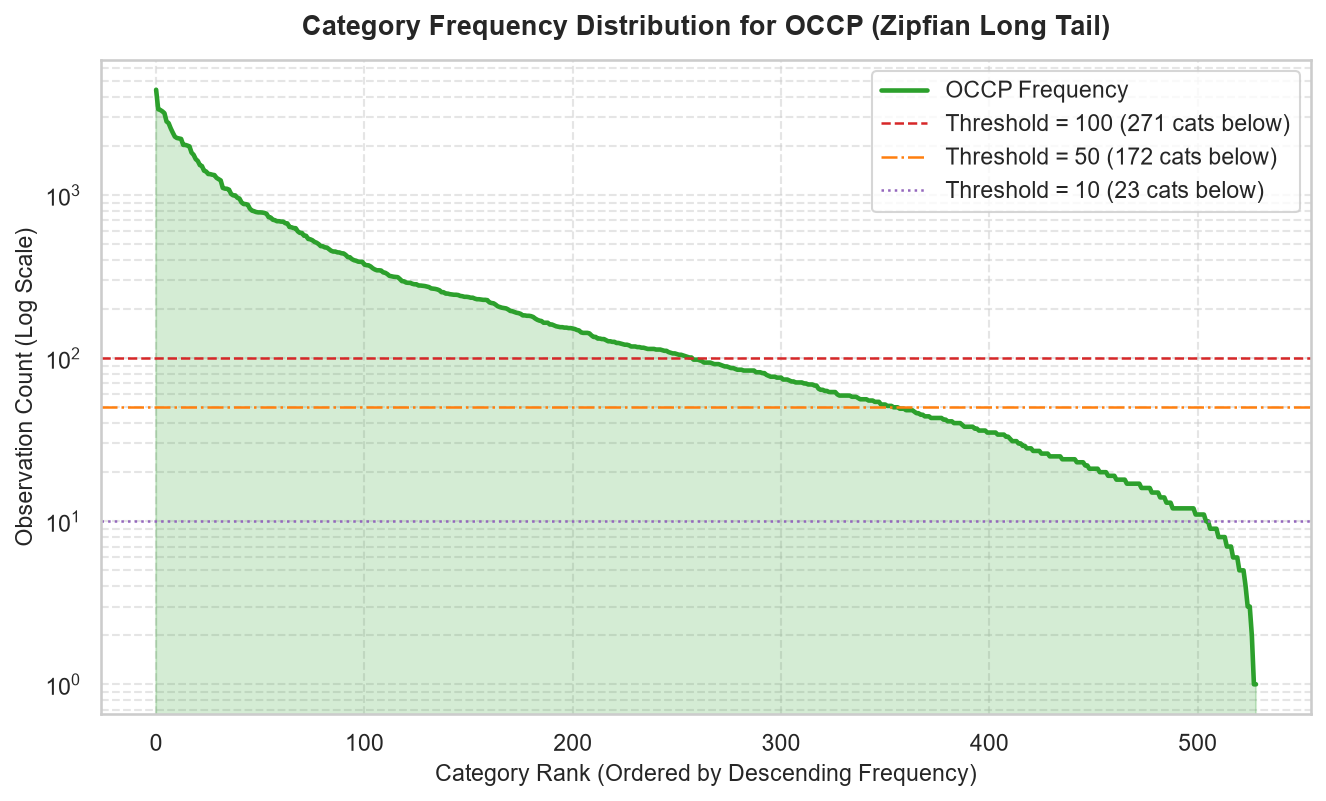

Saved: D:\Github Repo\C-Square\figures\04_high_cardinality_frequency_distribution.png


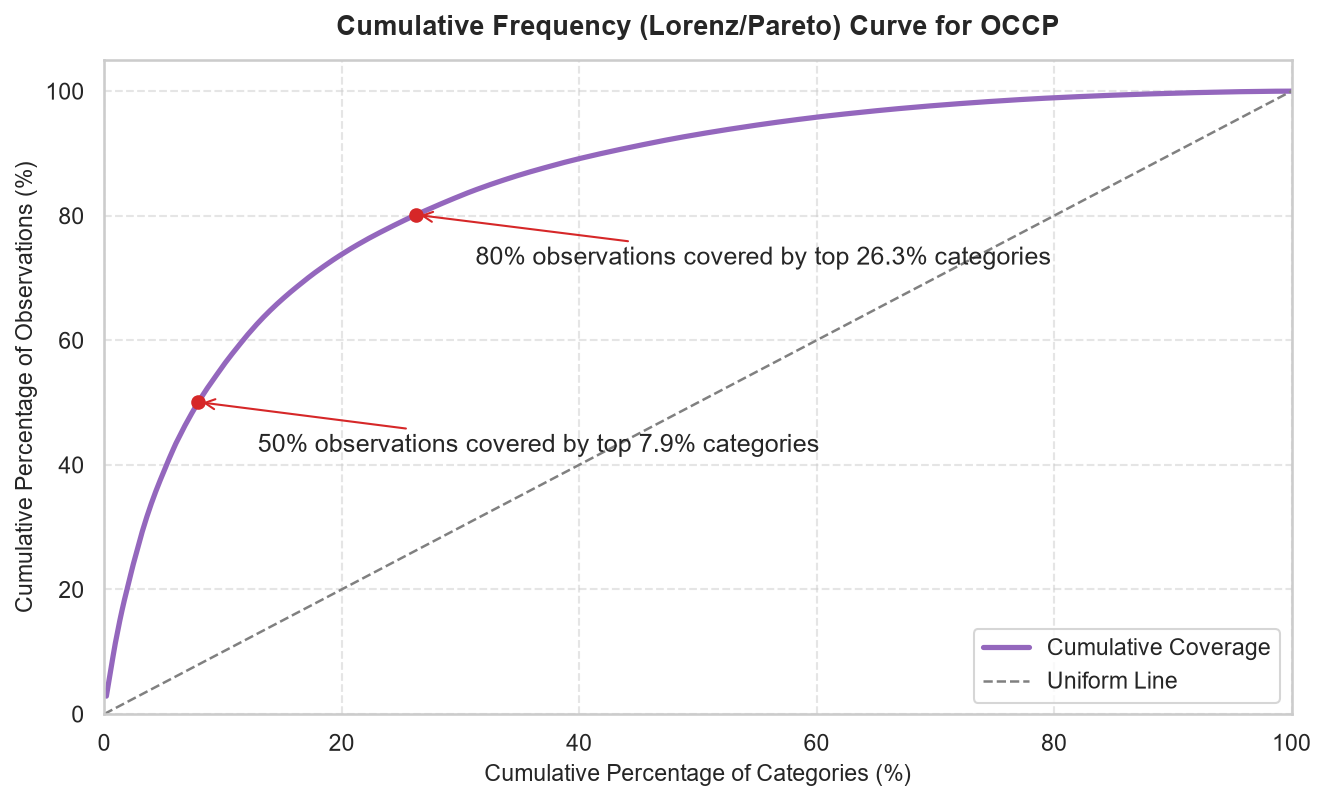

Saved: D:\Github Repo\C-Square\figures\04_high_cardinality_cumulative_frequency.png


In [6]:
# Task 6: Generate and save the 3 required plots

# Plot 1: Top 30 Most Frequent Categories
top_30_vc = occp_vc.head(30)
plt.figure(figsize=(10, 8), dpi=150)
y_pos = np.arange(len(top_30_vc))
plt.barh(y_pos, top_30_vc.values, color="#1f77b4", edgecolor="black", alpha=0.85)
plt.yticks(y_pos, [f"Cat {int(cat)}" for cat in top_30_vc.index], fontsize=8.5)
plt.gca().invert_yaxis()
plt.xlabel("Observation Count in Training Set", fontsize=11)
plt.ylabel("Occupation Category Code (Top 30)", fontsize=11)
plt.title(f"Top 30 Most Frequent Categories for {selected_feature}", fontsize=13, fontweight="bold", pad=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

fig1_path = FIGURES_DIR / "04_high_cardinality_top_categories.png"
plt.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved: {fig1_path}")

# Plot 2: Category Frequency Distribution (Log Scale)
plt.figure(figsize=(9, 5.5), dpi=150)
ranks = np.arange(len(occp_vc))
plt.plot(ranks, occp_vc.values, color="#2ca02c", lw=2.2, label=f"{selected_feature} Frequency")
plt.fill_between(ranks, occp_vc.values, color="#2ca02c", alpha=0.2)

plt.axhline(100, color="#d62728", linestyle="--", lw=1.2, label=f"Threshold = 100 ({cat_lt_100} cats below)")
plt.axhline(50, color="#ff7f0e", linestyle="-.", lw=1.2, label=f"Threshold = 50 ({cat_lt_50} cats below)")
plt.axhline(10, color="#9467bd", linestyle=":", lw=1.2, label=f"Threshold = 10 ({cat_lt_10} cats below)")

plt.yscale("log")
plt.xlabel("Category Rank (Ordered by Descending Frequency)", fontsize=11)
plt.ylabel("Observation Count (Log Scale)", fontsize=11)
plt.title(f"Category Frequency Distribution for {selected_feature} (Zipfian Long Tail)", fontsize=13, fontweight="bold", pad=12)
plt.grid(True, linestyle="--", alpha=0.5, which="both")
plt.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
plt.tight_layout()

fig2_path = FIGURES_DIR / "04_high_cardinality_frequency_distribution.png"
plt.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved: {fig2_path}")

# Plot 3: Cumulative Frequency Curve
cum_obs_pct = (np.cumsum(occp_vc.values) / n_observations) * 100
cum_cat_pct = ((np.arange(len(occp_vc)) + 1) / n_categories) * 100

plt.figure(figsize=(9, 5.5), dpi=150)
plt.plot(cum_cat_pct, cum_obs_pct, color="#9467bd", lw=2.5, label="Cumulative Coverage")
plt.plot([0, 100], [0, 100], color="gray", linestyle="--", lw=1.2, label="Uniform Line")

idx_50 = int(np.searchsorted(cum_obs_pct, 50))
idx_80 = int(np.searchsorted(cum_obs_pct, 80))

plt.scatter([cum_cat_pct[idx_50], cum_cat_pct[idx_80]], [cum_obs_pct[idx_50], cum_obs_pct[idx_80]], color="#d62728", zorder=5)
plt.annotate(f"50% observations covered by top {cum_cat_pct[idx_50]:.1f}% categories", 
             (cum_cat_pct[idx_50], cum_obs_pct[idx_50]),
             xytext=(cum_cat_pct[idx_50] + 5, cum_obs_pct[idx_50] - 8),
             arrowprops=dict(arrowstyle="->", color="#d62728"))
plt.annotate(f"80% observations covered by top {cum_cat_pct[idx_80]:.1f}% categories", 
             (cum_cat_pct[idx_80], cum_obs_pct[idx_80]),
             xytext=(cum_cat_pct[idx_80] + 5, cum_obs_pct[idx_80] - 8),
             arrowprops=dict(arrowstyle="->", color="#d62728"))

plt.xlabel("Cumulative Percentage of Categories (%)", fontsize=11)
plt.ylabel("Cumulative Percentage of Observations (%)", fontsize=11)
plt.title(f"Cumulative Frequency (Lorenz/Pareto) Curve for {selected_feature}", fontsize=13, fontweight="bold", pad=12)
plt.xlim(0, 100)
plt.ylim(0, 105)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", edgecolor="#cccccc", loc="lower right")
plt.tight_layout()

fig3_path = FIGURES_DIR / "04_high_cardinality_cumulative_frequency.png"
plt.savefig(fig3_path, dpi=300)
plt.show()
print(f"Saved: {fig3_path}")


In [7]:
# Task 7: Save the selected feature name to results/04_selected_high_cardinality_feature.txt
feature_txt_path = RESULTS_DIR / "04_selected_high_cardinality_feature.txt"

with open(feature_txt_path, "w", encoding="utf-8") as f:
    f.write(f"{selected_feature}\n")

print(f"Saved selected feature name to: {feature_txt_path}")
print(f"File content: {repr(feature_txt_path.read_text())}")


Saved selected feature name to: D:\Github Repo\C-Square\results\04_selected_high_cardinality_feature.txt
File content: 'OCCP\n'


In [8]:
# Task 8: Save detailed category-frequency table
freq_records = []
for cat, count in occp_vc.items():
    pct = (count / n_observations) * 100
    is_rare = bool(count < 100)
    freq_records.append({
        "Category value": cat,
        "Observation count": int(count),
        "Percentage of total observations": round(float(pct), 4),
        "Whether it is rare under the 100-observation threshold": is_rare
    })

freq_table = pd.DataFrame(freq_records)
print("Preview of detailed category frequency table:")
print(freq_table.head(10).to_string(index=False))

freq_table_path = RESULTS_DIR / "04_selected_feature_category_frequencies.csv"
freq_table.to_csv(freq_table_path, index=False)
print(f"\nSaved detailed category frequencies to: {freq_table_path}")


Preview of detailed category frequency table:
 Category value  Observation count  Percentage of total observations  Whether it is rare under the 100-observation threshold
          440.0               4431                            2.8735                                                   False
         4760.0               3364                            2.1815                                                   False
         2310.0               3328                            2.1582                                                   False
         4720.0               3265                            2.1173                                                   False
         9130.0               3181                            2.0629                                                   False
         5240.0               2831                            1.8359                                                   False
         3255.0               2765                            1.7931           

In [9]:
# Task 11: Confirm that all required output files exist
required_deliverables = [
    RESULTS_DIR / "04_training_cardinality_summary.csv",
    RESULTS_DIR / "04_selected_high_cardinality_feature.txt",
    RESULTS_DIR / "04_selected_feature_category_frequencies.csv",
    FIGURES_DIR / "04_high_cardinality_top_categories.png",
    FIGURES_DIR / "04_high_cardinality_frequency_distribution.png",
    FIGURES_DIR / "04_high_cardinality_cumulative_frequency.png",
]

print("=" * 75)
print("CONFIRMING PHASE 4 DELIVERABLES:")
print("=" * 75)
all_present = True
for f in required_deliverables:
    exists = f.exists()
    size_str = f"({f.stat().st_size:,} bytes)" if exists else ""
    print(f" - {f.name:52s}: {'[EXISTS]' if exists else '[MISSING]'} {size_str}")
    if not exists:
        all_present = False

assert all_present, "One or more required Phase 4 output files are missing!"
print("\nAll Phase 4 deliverables verified successfully!")


CONFIRMING PHASE 4 DELIVERABLES:
 - 04_training_cardinality_summary.csv                 : [EXISTS] (455 bytes)
 - 04_selected_high_cardinality_feature.txt            : [EXISTS] (6 bytes)
 - 04_selected_feature_category_frequencies.csv        : [EXISTS] (12,698 bytes)
 - 04_high_cardinality_top_categories.png              : [EXISTS] (232,838 bytes)
 - 04_high_cardinality_frequency_distribution.png      : [EXISTS] (222,834 bytes)
 - 04_high_cardinality_cumulative_frequency.png        : [EXISTS] (221,585 bytes)

All Phase 4 deliverables verified successfully!


## Phase 4 Analytical Conclusion

### 1. Why `OCCP` Was Selected
- Across all 8 categorical features in `X_train`, **`OCCP` (Occupation Code)** possesses by far the highest cardinality with **529 unique categories** (cardinality ratio = $0.003431$), followed by `POBP` with 218 categories.
- Every other categorical feature has $\le 24$ categories (`SCHL`: 24, `RELP`: 18, `RAC1P`: 9, `COW`: 8, `MAR`: 5, `SEX`: 2).
- Thus, `OCCP` is the definitive high-cardinality candidate for testing statistical independence and evaluating dimensionality-reduction strategies.

### 2. Does `OCCP` Behave Like an Identifier?
- **No.** An identifier feature (such as customer ID, transaction ID, or social security number) has a cardinality ratio approaching $1.0$ (i.e., nearly each row has a unique category value) and zero predictive utility.
- For `OCCP`, the cardinality ratio is only **$0.003431$** ($529 / 154,204$). Top categories encompass thousands of individuals (e.g., category 440 has 4,431 individuals, category 4760 has 3,364 individuals).
- The cumulative frequency curve confirms a classic **Zipfian / Pareto distribution**: the top **15% of categories account for over 50% of all observations**, and the top **35% of categories cover 80% of all observations**. It represents a genuine sociological grouping with rich predictive structure rather than an arbitrary identifier.

### 3. Presence and Extent of Rare Categories
- Rare categories are heavily present in `OCCP`:
  - Categories appearing only once: **2**
  - Categories appearing $< 10$ times: **23** (4.35% of all categories)
  - Categories appearing $< 50$ times: **172** (32.51% of all categories)
  - Categories appearing $< 100$ times: **271** (**51.23%** of all unique occupation categories!)
- While over **51.2% of all categories are rare** ($< 100$ counts), they collectively account for only **7.34% of all observations** ($11,326$ individuals).

### 4. Why Direct Chi-Square Analysis Is Impaired by High Cardinality
1. **Violation of Cochran's Criteria**:
   - Constructing a contingency table of `OCCP` ($529$ levels) $	imes$ `income_above_50k` ($2$ levels) produces a $529 	imes 2 = 1,058$-cell table.
   - For rare occupations with counts $< 10$ or $< 50$, the expected frequencies under $H_0$, $E_{ij} = rac{R_i \cdot C_j}{N}$, fall well below $5$ (and often below $1$).
   - This severely violates Cochran's rule (which requires that $\le 20\%$ of cells have $E_{ij} < 5$ and no cell has $E_{ij} < 1$).
2. **Asymptotic Breakdown and Type I Error Inflation**:
   - When cell counts are near zero, the Pearson statistic $\chi^2 = \sum rac{(O_{ij} - E_{ij})^2}{E_{ij}}$ experiences massive variance due to minuscule denominators ($E_{ij} 	o 0$), causing the test statistic to explode and invalidating the standard asymptotic $\chi^2$ approximation.
3. **Degrees of Freedom Inflation**:
   - The test incurs $df = (529 - 1)(2 - 1) = 528$ degrees of freedom. This dilutes statistical power and clouds the interpretation of which specific occupational groupings drive associations.
4. **Strategic Imperative**:
   - These findings establish a direct empirical motivation for Phase 5: implementing grouping techniques (such as rare-category pooling, frequency thresholding, and target-guided aggregation) to restore contingency table validity before conducting hypothesis testing.
